# HW3 — Custom image stitching

This report documents tasks 1–5. The figures, matrices, errors, retained-image lists, and compliance checks are generated by the code cells. A successful run is not automatically an assignment-complete result: task 5 requires at least four **successfully rendered** images, all their pair overlaps verified, and no measured pair above 80%.

## Reproduction and files

1. Install Python 3.12 and run `python -m pip install -r Homework/3/requirements.txt` from the repository root. The tested environment has the packages printed by the setup cell. First-time model loading requires internet to download pretrained weights.
2. Keep the source directories `io/`, `matching/`, and `warping/` together with `report.ipynb`, `camera_cal.json`, and the capture folders. Set `INPUT_FOLDER`, `CALIBRATION_FILE`, `DEVICE`, `MAX_KEYPOINTS`, and overlap limits in the setup cell, then run all cells in order. Relative folder paths are resolved against HW3.
3. Use calibration for the same camera, crop, focus, and resolution as the input. The supplied JSON has no calibration-resolution metadata, so this cannot be checked automatically. The notebook prints the input dimensions and calibration matrix for inspection.
4. Review the correspondence figures and overlap audit, the rejected-warp list, and the task-5 compliance summary. Submit the executed notebook, its panorama images, and the accompanying source files. The source appendix lists each file's role.

Our code uses OpenCV for geometric primitives, not `cv2.Stitcher` or `Stitcher_create`. SuperPoint and LightGlue supply feature detection, description, and matching. Custom code controls selection, homography use, footprint checking, output canvas construction, masks, source ownership, and compositing.


1. Create a sequence of images with overlap

### Capture and preprocessing method

Capture one continuous, mostly rotational sweep of a static scene. Keep some textured scene content visible between neighboring views. Lock exposure, white balance, and focus where possible; rotate near the optical center to reduce parallax. Aim for roughly 40–70% overlap between retained views, rather than relying on a dense video sampling rate to satisfy the final overlap limit.

The existing `ImageCapture(camera_path, save_path, extension='.jpg', capture_rate=5)` opens a webcam index or video/RTSP source, saves every fifth successfully read frame, displays the stream, and stops on `q` or end-of-stream. `capture_rate` is a frame interval, **not frames per second**. For a 30-fps source, a value of 5 samples at about 6 fps. That example does not establish the actual source's frame rate. Natural filename sorting restores time order (`frame_5` before `frame_10`). The reader ignores unreadable and unsupported files; put only one sequence in the selected folder.

Before extraction, undistort each image using the intrinsic matrix

\[
K=\begin{bmatrix}f_x&0&c_x\\0&f_y&c_y\\0&0&1\end{bmatrix}.
\]

The focal lengths \(f_x,f_y\) are in pixels, and \((c_x,c_y)\) is the principal point. For the five-coefficient calibration supplied here, normalized coordinates \(x,y\), radius \(r^2=x^2+y^2\), radial coefficients \(k_1,k_2,k_3\), and tangential coefficients \(p_1,p_2\) describe distortion as

\[
L=1+k_1r^2+k_2r^4+k_3r^6,
\quad x_d=xL+2p_1xy+p_2(r^2+2x^2),
\]
\[
y_d=yL+p_1(r^2+2y^2)+2p_2xy,
\quad u_d=f_xx_d+c_x,\quad v_d=f_yy_d+c_y.
\]

`cv2.undistort` uses this model to resample a corrected image. Undistorting an all-white mask identifies pixels supported by the original image; eroding that mask prevents artificial border features. A before/after plot checks that correction actually changes the image, but cannot prove that the calibration is correct.


To collect a new sequence, edit the `__main__` settings in `io/image_capture.py`: use `camera_path=0` for a local webcam (or your actual stream URL), `save_path='Homework/3/new_sequence'` when launching from the repository root, and `capture_rate=5`. Run `python Homework/3/io/image_capture.py`, sweep the camera slowly, and press `q` to finish. Then set `INPUT_FOLDER=Path('new_sequence')` in this report and use calibration for that camera. These are instructions for a new capture; the original capture frame rate and device settings were not logged and are not inferred from filenames.

Set `INPUT_FOLDER` to an image folder. Candidates are scanned in natural filename order. The overlap filter retains frames only when their estimated footprint overlap is at most `MAX_OVERLAP` (80%) with every previously retained frame, and at least `MIN_OVERLAP` (15%) with the last retained frame. Unreliable alignments are skipped and logged. Four retained images are required for the assignment. If fewer are found, the report marks the assignment incomplete but still renders the usable result; overlap limits are not relaxed. This is a greedy, model-based estimate, not a ground-truth overlap guarantee. Selection runs once in the planar analysis. All panorama variants reuse those same images; cylindrical matching runs once and its results are shared with local alignment. The overlap limit is assessed in the selection model, not independently re-enforced in each rendering projection.

Selection checks at least 12 RANSAC inliers, a 25% inlier ratio, reprojection error, and spatial support. After finding an eligible frame, it examines up to three following candidates and favors strong, spread-out matches and overlap near 60%, with a small sharpness preference. Features from lookahead frames are reused. Detailed decisions remain in `pipeline.selection_log`; the progress bar reports retained frames. The hard overlap limits still apply, and lookahead does not guarantee a globally optimal subset.

If the quick selection finds fewer than four frames, the same selection stage searches alternative starting frames and backtracks through other ordered sequences. Direct pair measurements are cached, and all retained pairs still have to satisfy the overlap cap. It stops when a four-frame sequence is found; otherwise it reports the longest sequence supported by the measured constraints. This search may take longer on a redundant folder, but its result is cached and reused by every rendering.

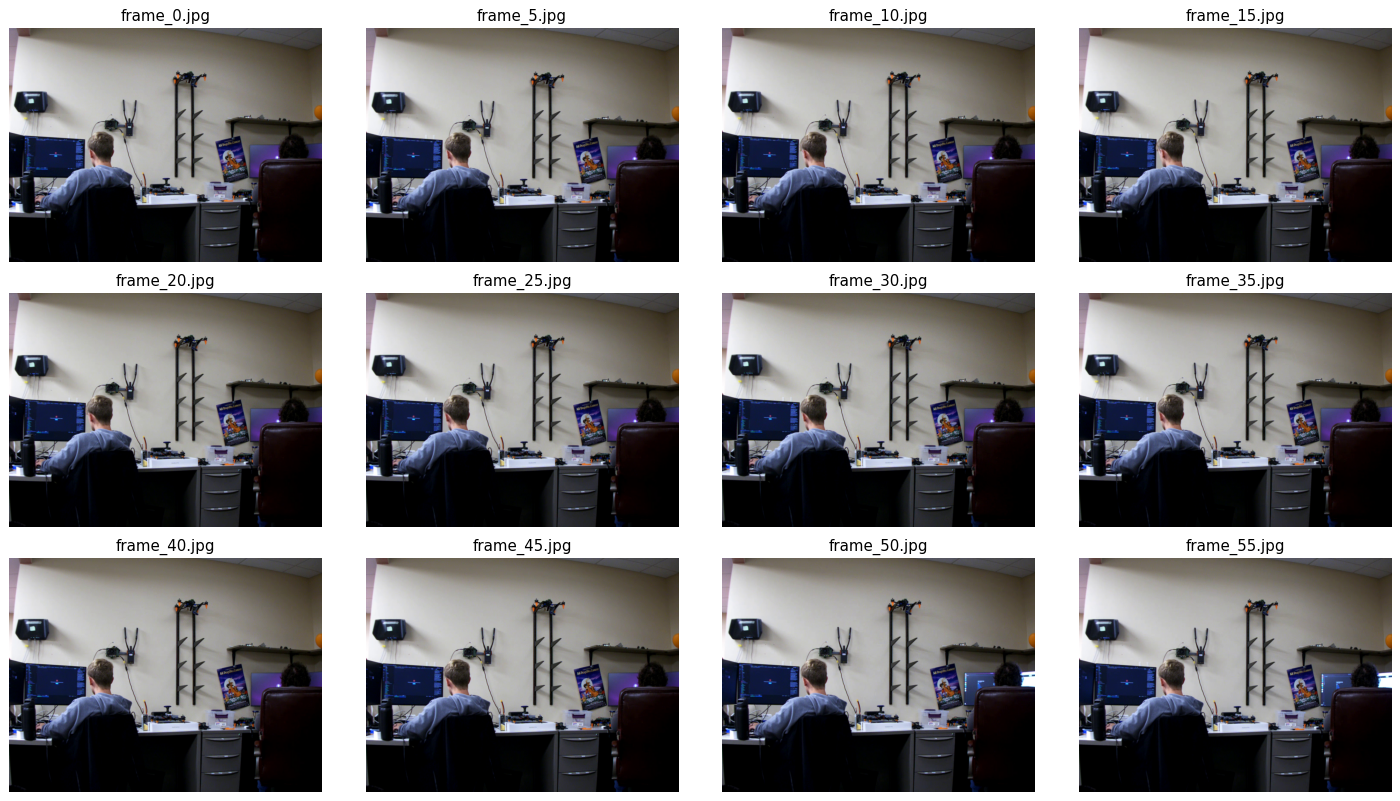

Stitcher loaded from: /home/megrad/Documents/GitHub/ME566/Homework/3/warping/stitch_images.py
Input folder: /home/megrad/Documents/GitHub/ME566/Homework/3/images_3
Scanning 85 images in natural order; redundant frames will be skipped.
First / last: frame_0.jpg / frame_420.jpg
Python: 3.12.3 OpenCV: 5.0.0
NumPy: 2.5.2 PyTorch: 2.13.0+cu130
Input dimensions (width, height): (1456, 1088)
Camera matrix:
 [[1.71901819e+03 0.00000000e+00 7.72796357e+02]
 [0.00000000e+00 1.71655060e+03 6.07691197e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion coefficients: [-0.48674218  0.19968696 -0.00462852 -0.00600952  0.06110686]


In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

HW3 = next(p for base in [Path.cwd(), *Path.cwd().parents]
           for p in [base, base / 'Homework' / '3']
           if (p / 'matching' / 'match_images.py').exists())
if str(HW3) not in sys.path:
    sys.path.insert(0, str(HW3))
# Reload edited modules so a running kernel does not retain old constructors.
import importlib

for module_name in ['warping.cam_undistort', 'warping.geometry', 'warping.warp_to_match',
                    'warping.cylindrical', 'warping.local_alignment',
                    'matching.overlap_filter', 'matching.sequence_search', 'matching.match_images',
                    'warping.stitch_images']:
    importlib.reload(importlib.import_module(module_name))
import warping.stitch_images as stitch_module
from matching.match_images import ImageMatcher
from warping.warp_to_match import WarpToMatch

ImageStitcher = stitch_module.ImageStitcher
print('Stitcher loaded from:', stitch_module.__file__)

DEVICE = 'cpu'
MAX_KEYPOINTS = 1024
MAX_OVERLAP = .80
MIN_OVERLAP = .15
# Change these paths to process a different sequence.
INPUT_FOLDER = Path('images_3')
CALIBRATION_FILE = HW3 / 'camera_cal.json'
sequence = (INPUT_FOLDER if INPUT_FOLDER.is_absolute() else HW3 / INPUT_FOLDER).resolve()
match_options = {
    'device': DEVICE,
    'max_keypoints': MAX_KEYPOINTS,
    'calibration': CALIBRATION_FILE,
}
pipeline = ImageMatcher(
    sequence, **match_options, max_overlap=MAX_OVERLAP, min_overlap=MIN_OVERLAP,
)
paths = pipeline.reader.image_paths
assert len(paths) >= 4, 'The report requires at least four readable images in the input folder.'
print(f'Input folder: {sequence}')
print(f'Scanning {len(paths)} images in natural order; redundant frames will be skipped.')
print('First / last:', paths[0].name, '/', paths[-1].name)
preview_count = min(12, len(paths))
columns = min(4, preview_count)
rows = (preview_count + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(16, 3 * rows), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, image, path in zip(axes.flat, pipeline.reader.images[:preview_count], paths[:preview_count]):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax.set_title(path.name)
plt.tight_layout(); plt.show()

# Record the execution environment and calibration used for reproducibility.
import json
import platform

import torch

print('Python:', platform.python_version(), 'OpenCV:', cv2.__version__)
print('NumPy:', np.__version__, 'PyTorch:', torch.__version__)
print('Input dimensions (width, height):', pipeline.reader.images[0].shape[1::-1])
print('Camera matrix:\n', pipeline.undistorter.camera_matrix)
print('Distortion coefficients:', pipeline.undistorter.dist_coeffs.ravel())


### Verify lens correction
The same calibration is applied before feature extraction. Straight scene edges should improve; this comparison does not establish that the calibration matches the camera. Cylindrical projection is a separate step.

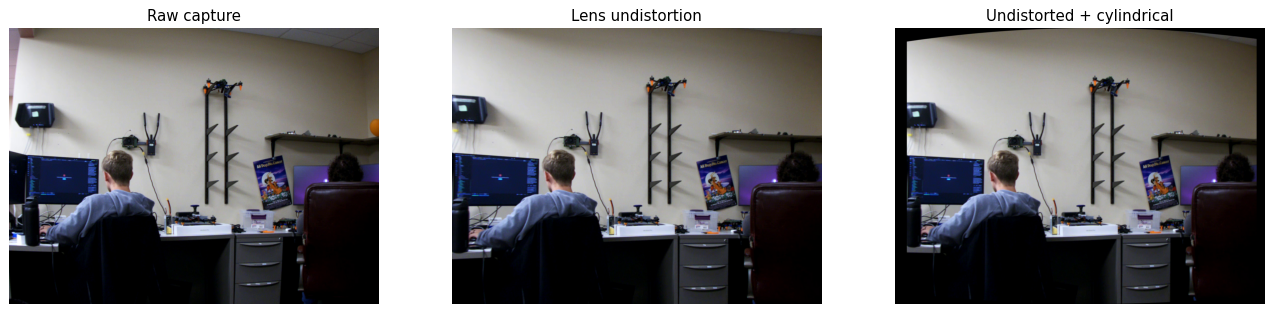

Mean absolute pixel change from undistortion: 12.996077126764167


In [2]:
from warping.cylindrical import CylindricalProjector

raw = pipeline.reader.images[0]
corrected = pipeline.undistorter.undistort(raw)
projector = CylindricalProjector(pipeline.undistorter.camera_matrix)
cylindrical, valid = projector.project(corrected)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, image, title in zip(axes, [raw, corrected, cylindrical],
                          ['Raw capture', 'Lens undistortion', 'Undistorted + cylindrical']):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis('off')
plt.show()
print('Mean absolute pixel change from undistortion:',
      np.abs(raw.astype(float) - corrected.astype(float)).mean())

2. Find the homography from one image to each other images. Demonstrate that it is correct. Show that the points in one image can be accurately matched to the other.

### Correspondences, homographies, and numerical evidence

`SuperPointObject` converts OpenCV BGR to grayscale, converts uint8 intensity \(I\) to \(I/255\), and extracts at most `MAX_KEYPOINTS` descriptors. Coordinates are `(x, y)` in original-resolution pixels because `extract(..., resize=None)` disables resizing. Each descriptor has 256 components. `LightGlueMatcher` uses `features='superpoint'` and returns pairs of integer indices into the two keypoint arrays. Models run in evaluation/inference mode on `DEVICE`.

A homography maps corresponding pixels by

\[
\lambda\begin{bmatrix}u\\v\\1\end{bmatrix}
=H\begin{bmatrix}x\\y\\1\end{bmatrix},\qquad
u=\frac{h_{11}x+h_{12}y+h_{13}}{h_{31}x+h_{32}y+h_{33}},\quad
v=\frac{h_{21}x+h_{22}y+h_{23}}{h_{31}x+h_{32}y+h_{33}}.
\]

\(H\) has eight independent parameters because an overall nonzero scale has no effect. Four distinct, non-collinear correspondences are the minimum. Our call is `findHomography(source, destination, RANSAC, 3.0)`; it maps the **second image into the first**, and the 3.0 threshold is in destination pixels. RANSAC repeatedly fits small samples, scores consensus, and refines the accepted model. With an inlier fraction \(w\), sample size \(s=4\), and desired success probability \(p\), the ideal independent-sampling iteration estimate is

\[
N=\frac{\log(1-p)}{\log(1-w^s)}.
\]

The implementation lets OpenCV use its default iteration budget/confidence rather than imposing this estimate. Poor matches can remain even after consensus; inspect their distribution, not just their number.

For \(H_{i-1\leftarrow i}\) mapping image \(i\) to its predecessor, the composition

\[
H_{0\leftarrow i}=H_{0\leftarrow i-1}H_{i-1\leftarrow i},\qquad
H_{i\leftarrow0}=H_{0\leftarrow i}^{-1}
\]

maps every selected image to image 0 and maps image 0 to every other selected image. The notebook prints these matrices and displays correspondence lines. For correspondence \((p_k,q_k)\), with \(\pi([a,b,c]^T)=[a/c,b/c]^T\), the forward residual is

\[
e_k=\|\pi(H\tilde p_k)-q_k\|_2,
\qquad \mathrm{RMSE}=\sqrt{\frac1M\sum_{k\in\mathcal I}e_k^2}.
\]

\(\mathcal I\) is the RANSAC inlier set and \(M\) its size. The median error and RMSE are reported in pixels. These are fit residuals, not independent ground-truth accuracy measurements. Repeated patterns, moving objects, and parallax can give locally good residuals but a poor panorama.

Selection first tests candidates with at least 12 inliers, at least 25% inlier ratio, inlier convex-hull area covering at least 1% of each image, and RMSE within the 3-pixel threshold. It ranks a short lookahead window using match support, coverage, sharpness, and spacing near 60% overlap. If that pass yields fewer than four images, an ordered backtracking search tests alternative starts and direct pair measurements. It reuses extracted features, caches its result, and never relaxes the overlap threshold merely to reach four images.


For reproducibility, the quick-pass ranking is
\[
S=2r+\min(n/100,1)+\min(c/0.2,1)+(1-|o-t|)
+0.15\min(\log(1+V)/8,1)-E/\tau.
\]
Here \(r\) is inlier fraction, \(n\) inlier count, \(c\) the smaller normalized inlier-hull coverage, \(o\) overlap with the anchor, \(t=\operatorname{clip}(0.60,o_{\min},o_{\max})\), \(V\) Laplacian variance, \(E\) inlier RMSE, and \(\tau=3\) pixels. The three-frame lookahead ranks eligible candidates by this score; geometry and overlap limits are checked first. It favors robust correspondence support and roughly 60% spacing, with only a modest sharpness contribution.

`ImageMatcher` undistorts and extracts features once per image. `WarpToMatch.estimate_homography()` uses RANSAC to map each next image into the preceding image. Composing these matrices maps every image into image 0; inverse matrices map image 0 into the other images. Errors below are inlier reprojection residuals, not independent ground-truth accuracy.

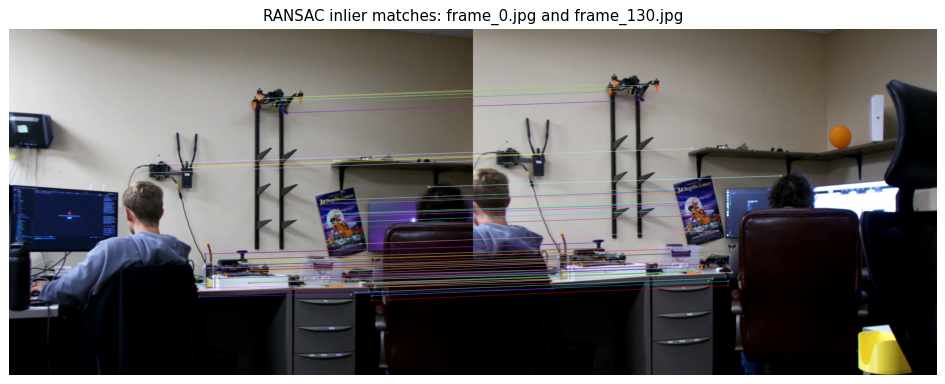

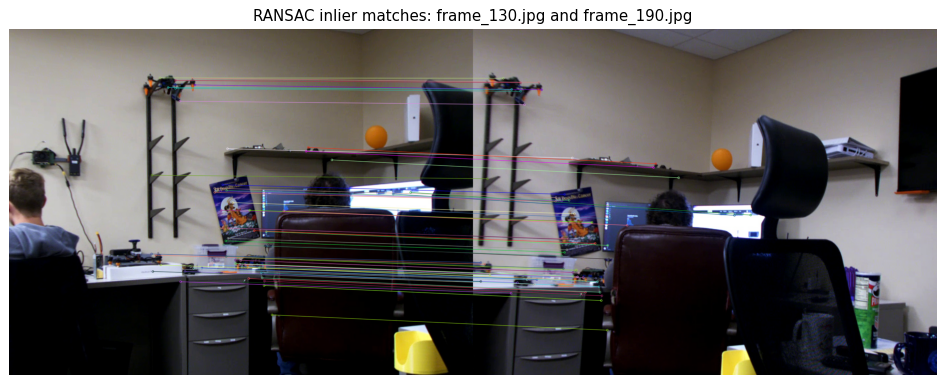

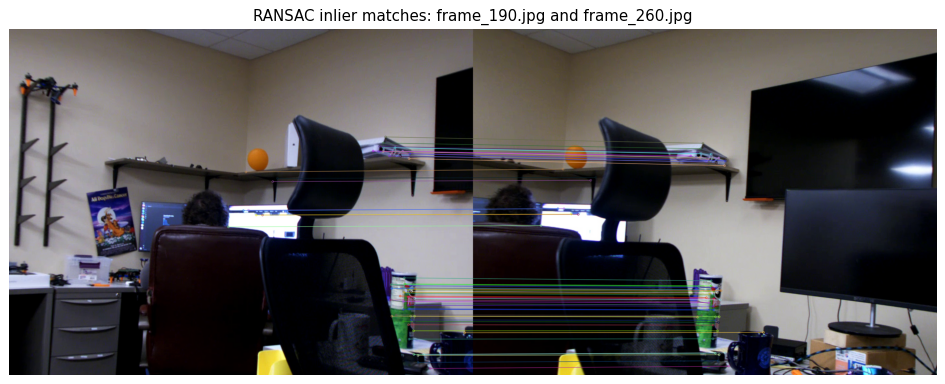

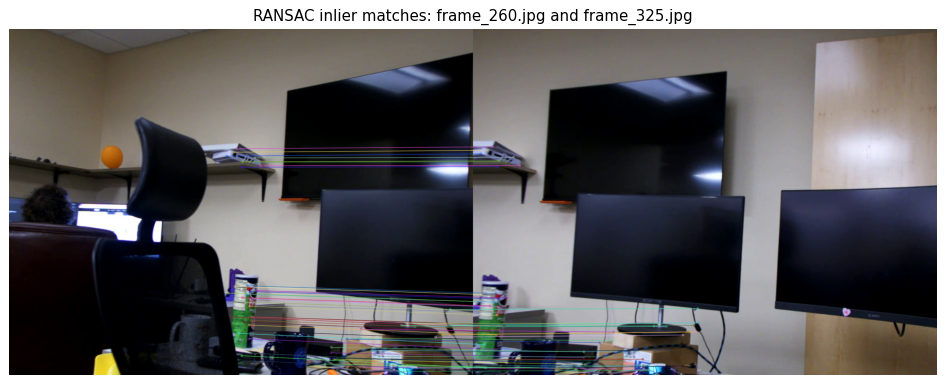

Selection decisions: {'too much overlap': 55, 'lower-ranked lookahead candidate': 11, 'selected': 4, 'unreliable alignment: need at least 12 inliers and 25% inlier ratio': 7, 'unreliable alignment: Footprint crosses projective infinity': 10}
Retained: ['frame_0.jpg', 'frame_130.jpg', 'frame_190.jpg', 'frame_260.jpg', 'frame_325.jpg']
Accepted 5 of 85 images.
frame_0.jpg <- frame_130.jpg: 374/469 inliers; median=1.29px; RMSE=1.52px
frame_130.jpg <- frame_190.jpg: 285/394 inliers; median=1.18px; RMSE=1.43px
frame_190.jpg <- frame_260.jpg: 95/283 inliers; median=1.41px; RMSE=1.71px
frame_260.jpg <- frame_325.jpg: 133/299 inliers; median=1.45px; RMSE=1.69px
H image 0 -> image 0:
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
H image 1 -> image 0:
[[ 8.23553152e-01 -1.56129012e-02  3.81094056e+02]
 [-5.57413629e-02  9.24071107e-01  7.07129168e+01]
 [-1.09106303e-04 -1.08752549e-05  1.00000000e+00]]
H image 2 -> image 0:
[[ 6.54810203e-01  5.54243555e-02  7.22574987e+02]
 [-1.79141985e-01  9.18231430e

In [3]:
pairs = pipeline.select_pairs()  # cached: rerunning this cell does not rescan
from collections import Counter

print('Selection decisions:', dict(Counter(row['reason'] for row in pipeline.selection_log)))
if not pipeline.selection_meets_requirement:
    display(Markdown(
        f'**Assignment incomplete:** retained {len(pipeline.selected_indices)} images; '
        f'{pipeline.min_images} required. Rendering continues with the usable frames. '
        'The 80% overlap limit has not been relaxed.'
    ))
if hasattr(pipeline, 'search_summary'):
    print('Alternative sequence search:', pipeline.search_summary)
selected_indices = pipeline.selected_indices.copy()
print('Retained:', [pipeline.reader.image_paths[i].name for i in pipeline.selected_indices])
print(f'Accepted {len(pipeline.selected_indices)} of {len(paths)} images.')
features = [pairs[0][1]] + [pair[2] for pair in pairs]
warper = WarpToMatch()
to_reference = [np.eye(3)]
for pair_number, (index, first, second, matches) in enumerate(pairs):
    name1, name2 = [paths[i].name for i in selected_indices[pair_number:pair_number + 2]]
    H = warper.estimate_homography(first.keypoints, second.keypoints, matches)
    inliers = warper.inlier_mask.copy()
    projected = cv2.perspectiveTransform(second.keypoints[matches[:, 1]][None], H)[0]
    errors = np.linalg.norm(projected - first.keypoints[matches[:, 0]], axis=1)
    to_reference.append(to_reference[-1] @ H)
    print(f'{name1} <- {name2}: {inliers.sum()}/{len(matches)} inliers; '
          f'median={np.median(errors[inliers]):.2f}px; RMSE={np.sqrt(np.mean(errors[inliers]**2)):.2f}px')
    view = pipeline.draw_matches(first, second, matches[inliers][:60])
    plt.figure(figsize=(14, 5)); plt.imshow(cv2.cvtColor(view, cv2.COLOR_BGR2RGB))
    plt.title(f'RANSAC inlier matches: {name1} and {name2}'); plt.axis('off'); plt.show()
for i, H in enumerate(to_reference):
    print(f'H image {i} -> image 0:\n{H / H[2, 2]}')
from_reference = [np.linalg.inv(H) for H in to_reference]
for i, H in enumerate(from_reference):
    print(f'H image 0 -> image {i}:\n{H / H[2, 2]}')


3. Determine the image size needed to create a panoramic of the images.

### Canvas calculation and containment

Transform the four boundary corners \((0,0),(w,0),(w,h),(0,h)\) of each image. The use of \(w,h\), rather than the last pixel indices, encloses the full pixel support. A denominator that reaches zero inside an image makes its planar footprint unbounded; such a warp is rejected.

For the retained transformed corners \((x_k,y_k)\), compute

\[
x_{\min}=\lfloor\min_kx_k\rfloor,\quad x_{\max}=\lceil\max_kx_k\rceil,
\quad y_{\min}=\lfloor\min_ky_k\rfloor,\quad y_{\max}=\lceil\max_ky_k\rceil,
\]
\[
W=x_{\max}-x_{\min},\quad H_c=y_{\max}-y_{\min},\quad
T=\begin{bmatrix}1&0&-x_{\min}\\0&1&-y_{\min}\\0&0&1\end{bmatrix}.
\]

\(W,H_c\) are output width and height; \(T\) translates every retained footprint into nonnegative canvas coordinates. The actual warp for image \(i\) is \(TH_{0\leftarrow i}\). The code asserts that every demonstrated corner lies in \([0,W]\times[0,H_c]\).

`panorama_layout()` rejects flipped/collapsed footprints, projected area outside 0.25–4 times the input area, edge scaling outside 0.25–4, canvas dimensions reaching 32767, and canvases exceeding 25,000,000 pixels. These are explicit engineering guards, not mathematical definitions of an incorrect homography. Rejection is reported and affects the final image count. We preserve native resolution and discard extreme warps instead of scaling them down to disguise expansion.

For task 5, pair overlap is estimated directly in one pair's coordinate system:

\[
o_{ij}=\frac{\operatorname{area}(P_i\cap P_j)}
{\min(\operatorname{area}(P_i),\operatorname{area}(P_j))}.
\]

\(P_i,P_j\) are convex image footprints from that pair's homography. This conservative normalization treats a small view nested inside a larger one as 100% overlap. Every retained pair must have \(o_{ij}\le0.8\), while consecutive retained images also need at least 15% overlap. These are model-based estimates. Area ratios change under projective coordinate transformations, so the audit does not reuse accumulated panorama-coordinate ratios. Unknown or unbounded pair geometry is reported as **UNKNOWN** and cannot pass the audit.


The `panorama_layout()` function checks each transformed footprint, rejects excessive stretching or oversized layouts, and returns a canvas for the retained images. Rejected images and reasons are printed. The canvas stays at native resolution; extreme warps are not rescued by shrinking them.

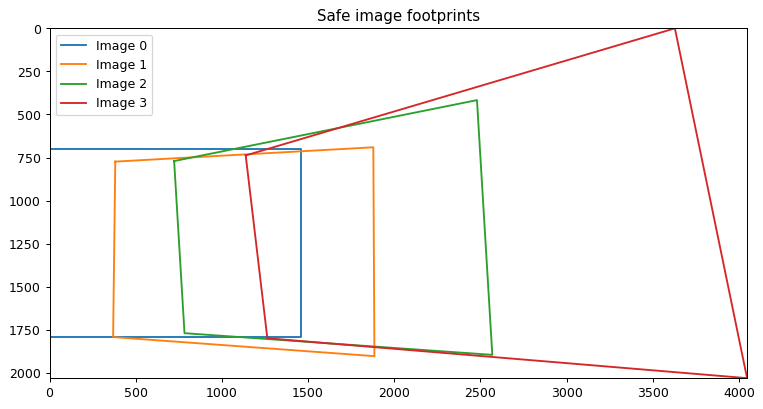

Canvas: 4048 x 2031 pixels (native resolution)
Rejected image 4: Projected area changes by 25.21x (limit 4x).
frame_0.jpg / frame_130.jpg: estimated overlap 71.5%
frame_0.jpg / frame_190.jpg: estimated overlap 47.3%
frame_0.jpg / frame_260.jpg: estimated overlap 34.2%
frame_0.jpg / frame_325.jpg: overlap UNKNOWN (Footprint crosses projective infinity)
frame_130.jpg / frame_190.jpg: estimated overlap 68.2%
frame_130.jpg / frame_260.jpg: estimated overlap 39.3%
frame_130.jpg / frame_325.jpg: overlap UNKNOWN (Footprint crosses projective infinity)
frame_190.jpg / frame_260.jpg: estimated overlap 66.1%
frame_190.jpg / frame_325.jpg: estimated overlap 20.8%
frame_260.jpg / frame_325.jpg: estimated overlap 53.0%
80% overlap check: UNVERIFIED: some pair overlaps could not be estimated


In [4]:
import importlib

from warping.geometry import panorama_layout

layout = panorama_layout([feature.image for feature in features], to_reference)
canvas_size, T = layout['size'], layout['transform']
print(f'Canvas: {canvas_size[0]} x {canvas_size[1]} pixels (native resolution)')
for rejection in layout['rejected']:
    print(f"Rejected image {rejection['index']}: {rejection['reason']}")
plt.figure(figsize=(10, 6))
for image_index, box in zip(layout['kept_indices'], layout['corners'], strict=True):
    mapped = np.column_stack((box, np.ones(4))) @ T.T
    closed = np.vstack([mapped, mapped[0]])
    plt.plot(closed[:, 0], closed[:, 1], label=f'Image {image_index}')
plt.xlim(0, canvas_size[0]); plt.ylim(canvas_size[1], 0)
plt.gca().set_aspect('equal'); plt.legend(); plt.title('Safe image footprints'); plt.show()

# Audit direct pair overlap, not accumulated panorama-coordinate area ratios.
# Area ratios change under projective transforms; direct estimates match selection.
# Refresh the audit implementation while preserving the existing selected pairs.
import matching.match_images as matching_module

matching_module = importlib.reload(matching_module)
overlap_rows = matching_module.ImageMatcher.selected_overlap_report(pipeline, pairs)
for row in overlap_rows:
    names = f"{paths[row['first']].name} / {paths[row['second']].name}"
    if row['overlap'] is None:
        print(f"{names}: overlap UNKNOWN ({row['reason']})")
    else:
        print(f"{names}: estimated overlap {row['overlap']:.1%}")
unknown_overlap = any(row['overlap'] is None for row in overlap_rows)
over_limit = any(row['overlap'] is not None and row['overlap'] > MAX_OVERLAP
                 for row in overlap_rows)
overlap_ok = bool(overlap_rows) and not unknown_overlap and not over_limit
if over_limit:
    overlap_status = 'FAIL: a measured pair exceeds the limit'
elif unknown_overlap or not overlap_rows:
    overlap_status = 'UNVERIFIED: some pair overlaps could not be estimated'
else:
    overlap_status = 'PASS (model estimate)'
print('80% overlap check:', overlap_status)


4. Create a program that warps an image using a homography. Warp an images to blank image and ensuyre that is is totally contained in the new image.

### Warping implementation

The program uses `warpPerspective(image, T @ H, (W, Hc))` with bilinear interpolation for image intensities. The input-to-output matrix is supplied without `WARP_INVERSE_MAP`; OpenCV internally samples the source for each output pixel, avoiding forward-mapping holes. The sampling relation is

\[
I_{\mathrm{out}}(u,v)=I_{\mathrm{in}}\!\left(\pi((TH)^{-1}[u,v,1]^T)\right).
\]

Values outside the source are filled with zero. A separate binary validity mask is warped with nearest-neighbor interpolation. This distinguishes empty canvas from valid black scene pixels. `warp_to_match.py` and `geometry.py` provide the source; the cell below demonstrates both the pair warp and a **single image on an otherwise blank canvas**. The assertion verifies full containment of the retained image, not just its match points. Rejected images are explicitly identified and are not counted as contained.


The custom `WarpToMatch` class already implements perspective warping and narrow-seam blending. Here it is called for a pair. The second demonstration uses its same OpenCV primitive (`warpPerspective`, not Stitcher) to warp one image onto the full-sequence blank canvas calculated above, and asserts corner containment.

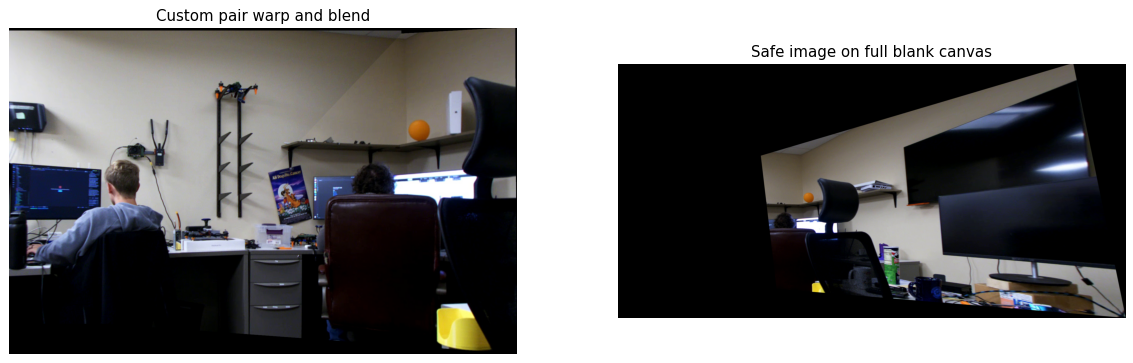

All four corners of the retained image are contained in the canvas.


In [5]:
from warping.geometry import WarpRejected, project_corners

index, first, second, matches = pairs[0]
try:
    pair_panorama = warper.warp(first.image, second.image, first.keypoints,
                               second.keypoints, matches)
except WarpRejected as exc:
    pair_panorama = None
    print(f'Pair demonstration rejected: {exc}')
image_index = layout['kept_indices'][-1]
H_canvas = T @ to_reference[image_index]
warped_image = cv2.warpPerspective(features[image_index].image, H_canvas, canvas_size)
translated_corners = project_corners(features[image_index].image, H_canvas)
assert np.all(translated_corners >= -1e-6)
assert np.all(translated_corners <= np.array(canvas_size) + 1e-6)
print('All four corners of the retained image are contained in the canvas.')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, image, title in zip(axes, [pair_panorama, warped_image],
                          ['Custom pair warp and blend', 'Safe image on full blank canvas']):
    if image is not None:
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    else:
        ax.text(.5, .5, 'Rejected extreme warp', ha='center', transform=ax.transAxes)
    ax.set_title(title); ax.axis('off')
plt.show()


5. Create a panoramic using the image sequence. Pleasae do no the use stitcher provided by open CV. Must use at least four images with no mare than 80% overlap between any two images. Discuss issues with the panoramic, what causes them, and how they might be fixed.

### Custom panorama and acceptance criteria

`ImageStitcher` processes the selected matches, maps each candidate into the current panorama coordinates, checks its geometry, warps the pixels and validity mask, and composites the result. If an extreme candidate is rejected, the next candidate is matched to the last successfully rendered image; a rejected image is never made the new anchor. Cached matches and the selected subset are reused across rendering comparisons.

To avoid transparent doubled edges from broad averaging, the default blend chooses the source farther from its valid border. If \(d_1,d_2\) are distances to those borders, define ownership \(A=1[d_1\ge d_2]\). A 5-by-5 Gaussian filter with standard deviation 0.8 pixels softens only the ownership boundary:

\[
\alpha=G_{5,0.8}*A,\qquad I=\alpha I_1+(1-\alpha)I_2.
\]

Masks force \(\alpha=1\) where only image 1 is valid and image-2 ownership where only image 2 is valid. Pixels covered by neither remain zero. This suppresses broad ghosting but can expose a seam when geometry or exposure differs.

The task-5 summary checks the **rendered** input count, rejected frames, and all measured pair overlaps. It must not claim completion with only two or three rendered images or an unknown overlap among those rendered images. A panorama can be useful even when it does not satisfy the grading constraints.


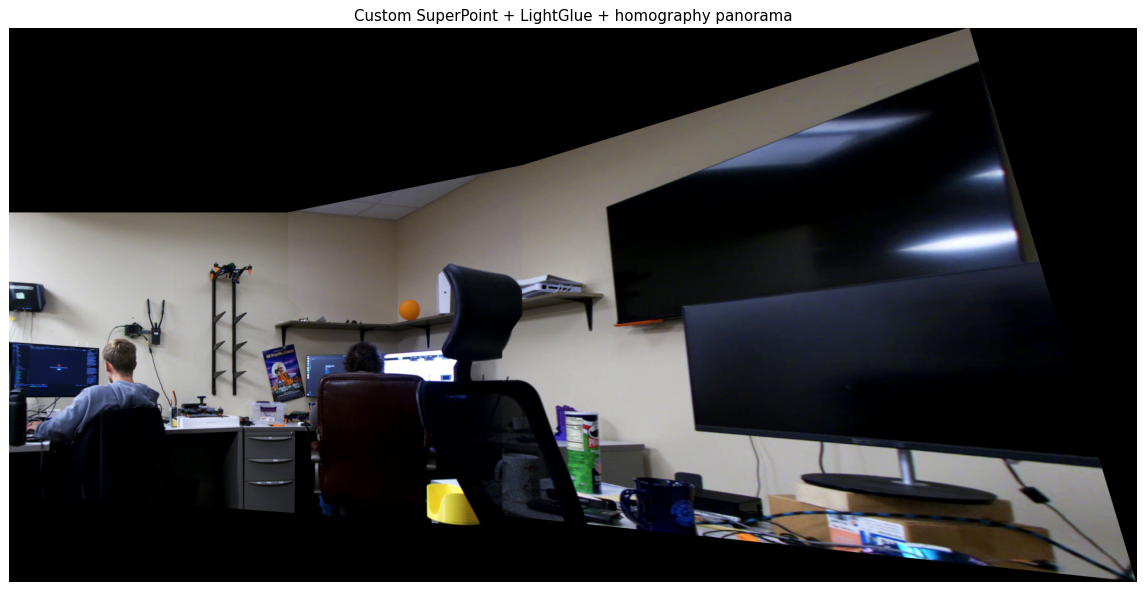

Rejected warp for frame_325.jpg: Projected area changes by 45.86x (limit 4x).
Stitching images: 100%|##########| 4/4 [00:00<00:00,  5.83pair/s, inliers=62, matches=283]
Saved: /home/megrad/Documents/GitHub/ME566/Homework/3/outputs/stitches/images_3/panorama.jpg
Panorama dimensions: 4286 x 2107
Rendered pair frame_0.jpg / frame_130.jpg: 71.5%
Rendered pair frame_0.jpg / frame_190.jpg: 47.3%
Rendered pair frame_0.jpg / frame_260.jpg: 34.2%
Rendered pair frame_130.jpg / frame_190.jpg: 68.2%
Rendered pair frame_130.jpg / frame_260.jpg: 39.3%
Rendered pair frame_190.jpg / frame_260.jpg: 66.1%
Successfully rendered inputs: ['frame_0.jpg', 'frame_130.jpg', 'frame_190.jpg', 'frame_260.jpg']
Rejected warps: [{'path': '/home/megrad/Documents/GitHub/ME566/Homework/3/images_3/frame_325.jpg', 'reason': 'Projected area changes by 45.86x (limit 4x).'}]
Task 5: PASS: >=4 rendered images and measured overlaps <=80%
Reproduction manifest: /home/megrad/Documents/GitHub/ME566/Homework/3/outputs/stitches/i

In [6]:
stitcher = ImageStitcher(sequence, **match_options)
panorama = stitcher.stitch(pairs=pairs, selected_indices=selected_indices)
print('Saved:', stitcher.output_path)
print('Panorama dimensions:', panorama.shape[1], 'x', panorama.shape[0])
plt.figure(figsize=(18, 8)); plt.imshow(cv2.cvtColor(panorama, cv2.COLOR_BGR2RGB))
plt.title('Custom SuperPoint + LightGlue + homography panorama'); plt.axis('off'); plt.show()
rendered_names = [p.name for p in stitcher.selected_paths]
rejected_names = stitcher.rejected_warps
from report_helpers import audit_rendered_panorama

rendered_audit = audit_rendered_panorama(pipeline, pairs, stitcher.selected_paths, MAX_OVERLAP)
assignment_complete = rendered_audit['complete']
for row in rendered_audit['overlaps']:
    label = f"{paths[row['first']].name} / {paths[row['second']].name}"
    print(f"Rendered pair {label}: {row['overlap']:.1%}" if row['overlap'] is not None
          else f"Rendered pair {label}: UNKNOWN ({row['reason']})")
print('Successfully rendered inputs:', rendered_names)
print('Rejected warps:', rejected_names)
print('Task 5:', 'PASS: >=4 rendered images and measured overlaps <=80%' if assignment_complete
      else 'INCOMPLETE: inspect rendered count, rejected warps, and overlap audit')
manifest = {
    'input_folder': str(sequence), 'calibration': str(CALIBRATION_FILE),
    'device': DEVICE, 'max_keypoints': MAX_KEYPOINTS,
    'max_overlap': MAX_OVERLAP, 'min_overlap': MIN_OVERLAP,
    'selected_inputs': [str(paths[i]) for i in selected_indices],
    'rendered_inputs': [str(p) for p in stitcher.selected_paths],
    'rejected_warps': rejected_names, 'overlap_audit': rendered_audit['overlaps'],
    'task5_complete': assignment_complete,
    'panorama_size': list(panorama.shape[1::-1]),
    'versions': {'python': platform.python_version(), 'opencv': cv2.__version__,
                 'numpy': np.__version__, 'torch': torch.__version__},
}
manifest_path = stitcher.output_path.with_name('run_manifest.json')
manifest_path.write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print('Reproduction manifest:', manifest_path)


### Executed result for `images_3`

The input folder contains 85 images at 1456 × 1088 pixels. The scan selected frames 0, 130, 190, 260, and 325. The planar renderer rejected frame 325 because its projected area expanded by 45.86 times, leaving **four successfully rendered images**: 0, 130, 190, and 260. The final native-resolution panorama is **4286 × 2107 pixels**. The layout demonstration is slightly smaller (4048 × 2031) because it uses composed pair estimates, whereas incremental rendering re-estimates correspondences in the current panorama frame.

All six direct overlap estimates among the rendered images are known: 71.5%, 47.3%, 34.2%, 68.2%, 39.3%, and 66.1%. Their maximum is **71.5%**, below 80%. Adjacent selected-pair inlier RMSEs before rendering are 1.52, 1.43, and 1.71 pixels for the first four frames. The run manifest records these source names, parameters, versions, audit status, output dimensions, and the rejected candidate. These figures describe this executed example; rerunning another folder must use its generated measurements.

The output covers the room continuously, but the right-hand monitors are enlarged and tilted, the upper boundary slopes, and black wedges surround the warped footprints. These arise from mapping a wide sweep onto a single plane and from finite image support. The nearby chair and distant walls occupy different depths, so translation/parallax and moving subjects can create mismatched edges even when the homography residual is small. The five-pixel ownership transition reduces cloudy averaging but does not solve geometric disagreement. Camera-centered rotation and static subjects improve capture; cylindrical projection reduces planar stretching; global refinement reduces accumulated drift; exposure locking reduces brightness discontinuities; and coverage-based cropping can remove empty wedges at the cost of field of view. Bounded local flow is optional and may deform object edges, so its output must be inspected rather than assumed superior.


The pipeline uses our `ImageStitcher`, `ImageMatcher`, `CameraUndistorter`, SuperPoint/LightGlue wrappers, and `WarpToMatch`; it never calls OpenCV Stitcher.

Interpret the displayed panorama and measurements together. Possible issues and remedies:

- **Double edges or ghosting:** camera translation produces parallax at different scene depths, or subjects move. Rotate about the camera center, use a static scene, or use local warps and seam selection.
- **Brightness seams:** automatic exposure or white balance differs between frames. Lock camera settings or add exposure compensation and multiband blending; narrow-seam blending alone cannot remove all seams.
- **Curved edges, stretching, or drift:** a planar homography is imperfect for a wide view, and sequential estimation accumulates error. Use cylindrical/spherical projection and global alignment refinement.
- **Black canvas regions:** transformed rectangular image footprints do not fill their enclosing rectangle. Crop to valid coverage rather than treating black pixels as missing image data.
- **Blur or unreliable correspondences:** motion blur, weak texture, or repeated patterns can reduce reliable matches. Capture sharper frames and inspect RANSAC residuals and match plots.

The reprojection residuals assess fit to selected correspondences; they do not prove global alignment. The footprint overlap is also an estimate based on those homographies. Only claim the four-image/80% requirement is met when the check passes and the displayed sequence supports it.

### Compare cylindrical projection and optional local alignment
The planar result above remains the homography homework demonstration. Cylindrical mode uses calibrated focal lengths and similarity alignment. Local alignment adds bounded optical-flow corrections in overlaps; it is experimental, does not correct camera calibration, and cannot guarantee removal of parallax or moving-object artifacts.

### Optional projection and local refinement: equations

Cylindrical projection is an additional comparison, not lens calibration. With cylindrical pixel coordinate \((u_c,v_c)\), focal length \(f=f_x\), and principal point \((c_x,c_y)\), the inverse sampling map is

\[
\theta=(u_c-c_x)/f,\quad
u=f\tan\theta+c_x,\qquad v=(v_c-c_y)/\cos\theta+c_y.
\]

`remap` samples the undistorted perspective image at \((u,v)\). Here the cylindrical vertical pixel scale is the original vertical pixel scale; \(f_y\) cancels in this inverse expression. After projection, RANSAC similarity alignment uses

\[
A=\begin{bmatrix}a&-b&t_x\\b&a&t_y\\0&0&1\end{bmatrix},\quad
s=\sqrt{a^2+b^2},\quad\phi=\operatorname{atan2}(b,a),
\]

where \(s,\phi,t_x,t_y\) describe uniform scale, in-plane rotation, and translation. This avoids reintroducing a full projective warp after cylindrical projection, but it does not guarantee a physically correct camera model.

Optional Farneback flow estimates a residual displacement \(F=(F_x,F_y)\) between globally aligned overlap images. The brightness-constancy assumption is \(I_1(x,y)\approx I_2(x+F_x,y+F_y)\). After estimation on an image at most 800 pixels on its longest side, flow is resized and its vector components scaled back to canvas pixels. Its magnitude is capped at 20 pixels, and it fades near the overlap boundary:

\[
F'=\min(1,20/\max(\|F\|,10^{-6}))\,
\min(d_{\mathrm{overlap}}/32,1)\,F.
\]

The corrected incoming image is sampled at \((x+F'_x,y+F'_y)\). This is a local appearance correction; transform matrices still describe only global alignment. Moving subjects, occlusions, and parallax can leave artifacts or be distorted by flow.


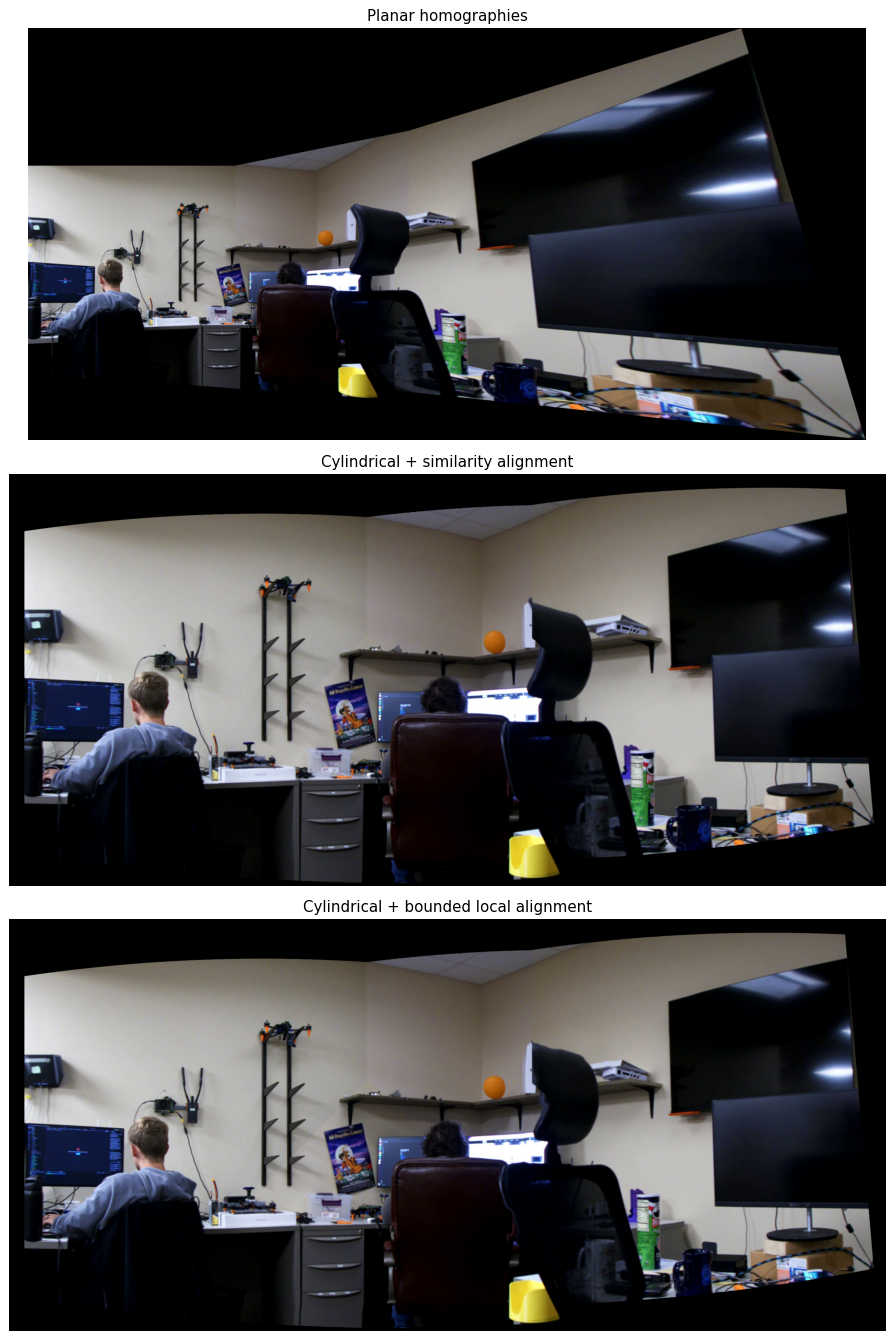

Stitching images: 100%|##########| 3/3 [00:00<00:00,  5.79pair/s, inliers=72, matches=287]
Cylindrical output: /home/megrad/Documents/GitHub/ME566/Homework/3/outputs/stitches/images_3/panorama_cylindrical.jpg
Local alignment output: /home/megrad/Documents/GitHub/ME566/Homework/3/outputs/stitches/images_3/panorama_cylindrical_local.jpg


In [7]:
cyl_options = dict(
    **match_options, selected_indices=[paths.index(path) for path in stitcher.selected_paths], projection='cylindrical',
)
cyl_stitcher = ImageStitcher(sequence, **cyl_options)
# Rematch the already-selected images in cylindrical coordinates just once.
cyl_pairs = cyl_stitcher.matcher.match_selected()  # no selector or skipping here
cyl_panorama = cyl_stitcher.stitch(pairs=cyl_pairs)
local_stitcher = ImageStitcher(sequence, **cyl_options, local_alignment=True)
local_panorama = local_stitcher.stitch(pairs=cyl_pairs)
fig, axes = plt.subplots(3, 1, figsize=(18, 15))
for ax, image, title in zip(axes, [panorama, cyl_panorama, local_panorama],
                          ['Planar homographies', 'Cylindrical + similarity alignment',
                           'Cylindrical + bounded local alignment']):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()
print('Cylindrical output:', cyl_stitcher.output_path)
print('Local alignment output:', local_stitcher.output_path)

**Comparison discussion.** Compare the outputs for the selected input folder. Inspect edge stretching, doubled object boundaries, exposure seams, and empty borders. Cylindrical projection and local alignment may help, but neither guarantees correct alignment for moving subjects or scenes with substantial parallax. Report observations from this run rather than assuming the results of another sequence apply. Both comparison renderings use the same successfully rendered four-image subset as the primary planar panorama. This avoids confusing extra coverage from a fifth input with an improvement from projection or blending.

6. EC (10 Pts): Create three panoramas from three difference image seqquences. Each panoramic should include at least ten images. Discuss issues witht the panoramic, what causes them, and how they might be fixed. 

## OpenCV calls and parameters used

The table records the Python calls in the supplied code. Unless overridden, geometric sampling uses `BORDER_CONSTANT` with border value 0; `resize` uses `INTER_LINEAR`. Pixel dimensions are passed as **(width, height)**. Dynamic names below refer to arrays/matrices generated by the preceding cells; they are not additional unknown tuning constants.

| Call in this implementation | Parameters and purpose |
|---|---|
| `VideoCapture(camera_path)`, `cap.isOpened()`, `cap.read()` | A webcam index, file, or RTSP URL opens the capture. `read()` returns success and one frame. The capture example samples every fifth frame (`capture_rate=5`). |
| `imshow('Camera Stream', frame)`, `waitKey(1)`, `cap.release()`, `destroyAllWindows()` | Display capture, wait about 1 ms for input, terminate on `q`, and release GUI/camera resources. Capture is optional; existing folders need no camera. |
| `imread(str(path))`, `imwrite(str(output), image)` | Default color decoding produces an 8-bit BGR image; unreadable paths return `None`. JPEG output uses the installed OpenCV encoder defaults because no encoding parameters are supplied. Return status is checked when writing final outputs. |
| `cvtColor(image, COLOR_BGR2GRAY)` | Convert BGR input to one intensity channel for SuperPoint or flow/sharpness measurements. The wrapper also accepts BGRA with `COLOR_BGRA2GRAY`. `COLOR_BGR2RGB` is used only for correct Matplotlib display. |
| `undistort(image, K, dist_coeffs)` | Correct radial/tangential lens distortion using the printed intrinsic matrix and saved coefficient vector. No replacement camera matrix is passed, so output intrinsics use `K`. Output dimensions match the input. |
| `erode(mask, ones((9,9), uint8))` | One default iteration removes a 4-pixel margin around internal invalid regions. Features in the remaining valid mask are retained. |
| `findHomography(source, destination, RANSAC, 3.0)` | Fit a 3-by-3 second-to-first projective map; 3.0 is the consensus reprojection threshold in destination pixels. Omitted `maxIters` and `confidence` use defaults 2000 and 0.995. Returns the matrix and inlier mask. |
| `perspectiveTransform(points[None], H)` | Apply a 3-by-3 projective matrix to 2D coordinates. The leading batch dimension satisfies OpenCV's point-array convention. No pixels are resampled. |
| `convexHull(points.astype(float32))`, `contourArea(hull)` | Compute inlier spatial support and polygon area. Hull defaults are `clockwise=False`, `returnPoints=True`; area is unsigned unless `oriented=True` is explicitly passed for footprint flip detection. |
| `Laplacian(gray, CV_32F)` | Compute sharpness as variance of the Laplacian. Output is float32, with defaults `ksize=1`, `scale=1`, `delta=0`, and reflected border. This has only a small influence on candidate ranking. |
| `warpPerspective(image, transform, size)` | Resample an image using an input-to-canvas homography, default `INTER_LINEAR`, and zero-filled constant border. No `WARP_INVERSE_MAP` flag is used. The binary-mask call explicitly sets `flags=INTER_NEAREST`. |
| `distanceTransform(padded_mask, DIST_L2, 3)` | Approximate Euclidean distance to zero-valued mask pixels using a 3-by-3 distance mask. Zero padding supplies a real boundary even when the image fills the canvas. |
| `GaussianBlur(ownership, (5,5), 0.8)` | Smooth source ownership across a narrow join with a 5-pixel kernel; `sigmaX=0.8`, default `sigmaY=0` derives the same vertical scale, and border mode is reflected. |
| `KeyPoint(float(x), float(y), 1)`, `DMatch(int(i), int(j), 0.0)` | Wrap detected pixel locations and match-index pairs for drawing. Keypoint size 1 and distance 0.0 are display metadata, not re-estimated descriptor distances. |
| `drawMatches(image1, k1, image2, k2, matches, None, flags=NOT_DRAW_SINGLE_POINTS)` | Make a side-by-side correspondence figure. `None` requests a newly allocated output; the flag suppresses unmatched keypoint markers. Only up to 60 inlier lines are plotted in the report for readability. |
| `remap(image, map_x, map_y, INTER_LINEAR)` | Sample cylindrical or flow-corrected coordinates using bilinear interpolation and zero border. Mask sampling explicitly uses `INTER_NEAREST`. |
| `estimateAffinePartial2D(source, destination, method=RANSAC, ransacReprojThreshold=3.0)` | Optional cylindrical similarity fit. Omitted defaults are `maxIters=2000`, `confidence=0.99`, and `refineIters=10`. Returns a 2-by-3 map augmented with `[0,0,1]`. |
| `resize(image, size)` | Optional flow estimation resizes intensities to at most 800 pixels on the longest side; estimated flow is resized back and its vector components rescaled. Default interpolation is bilinear. |
| `calcOpticalFlowFarneback(prev, next, None, .5, 3, 25, 4, 7, 1.5, 0)` | Optional local refinement: allocate new flow (`None`); pyramid scale 0.5; 3 pyramid levels; 25-pixel averaging window; 4 iterations per level; polynomial neighborhood 7; polynomial smoothing sigma 1.5; flags 0. This estimates residual flow, not camera motion or scene depth. |

The implemented source is the authority for parameters, and installed version numbers are printed at runtime. API references: [calibration and homography](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html), [geometric resampling](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html), and [optical flow](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html). Pretrained models: [LightGlue/SuperPoint implementation](https://github.com/cvg/LightGlue).


## Source code accompanying the write-up

Submit this executed notebook with the source tree and calibration, rather than an image-only export. The same source is packaged in `outputs/hw3_source.zip`.

| File | Role |
|---|---|
| `io/image_capture.py` | Capture the overlapping input sequence. |
| `io/image_reader.py` | Read supported images in natural order. |
| `matching/superpoint_class.py` | Grayscale normalization and learned keypoints/descriptors. |
| `matching/lightglue_class.py` | Learned correspondence estimation. |
| `matching/match_images.py` | Calibrated preprocessing, cached matching/selection, and overlap audit. |
| `matching/overlap_filter.py`, `matching/sequence_search.py` | Candidate quality checks, direct footprint overlap, and alternative-sequence search. |
| `warping/geometry.py` | Corner projection, geometry guards, finite canvas bounds, and layout functions. |
| `warping/warp_to_match.py` | RANSAC homography estimation, image/mask warping, source ownership, and blending functions. |
| `warping/stitch_images.py` | Custom panorama orchestration and rejection-aware anchoring. |
| `warping/cam_undistort.py` | Lens correction with the supplied calibration. |
| `warping/cylindrical.py`, `warping/local_alignment.py` | Optional cylindrical/similarity and bounded-flow comparisons. |
| `requirements.txt`, `camera_cal.json` | Dependency declaration and actual calibration values. |
| `report_helpers.py` | Audit only successfully rendered inputs without changing cached selection. |
| `tests/` | Regressions for selection reuse, overlap failures, rejected geometry, and anchor recovery. |

The capture folders contain the actual observations; do not replace missing data with generated scenes or reuse one sweep as three independent extra-credit sequences. The optional extra-credit task is complete only if **three distinct** capture sequences each produce at least ten successfully rendered input images, with an individual result discussion. This report does not assert extra-credit completion merely because three folders exist.
